# <div style="background-color:rgba(255, 255, 255, 0.1); text-align:center; vertical-align: middle; padding:40px 0; margin-top:30px"><span style="color:rgba(255, 255, 255, 1);"> Template</span></span></div>

In [7]:
# Hide unnecessary warnings.
import warnings
warnings.filterwarnings('ignore')

# Import PHYS231.py and then run the installer function.
import PHYS231
PHYS231.Installer()

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm # used to generate a sequence of colours for plotting
import pandas as pd
import scipy.stats as sp
from scipy.optimize import curve_fit
from IPython.display import HTML as html_print
from IPython.display import display, Markdown, Latex
import uncertainties
import math
import sys

In [9]:
from IPython.display import HTML, display


def variable_template_builder():
    html_code = """
    <div style="background-color: #1e1e1e; padding: 15px; border-radius: 8px; font-family: sans-serif; max-width: 520px; color: #ffffff; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
        <div style="margin-bottom: 10px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Variable Name(s) (comma-separated):</label>
            <input type="text" id="var_names_input" placeholder="e.g. theta_m, I, B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>
        <div style="margin-bottom: 14px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Units / Comment (Optional, comma-separated):</label>
            <input type="text" id="units_comment_input" placeholder="e.g. deg, A, T" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>
        <button id="copy_btn" onclick="copyAndReset()" style="width: 100%; padding: 10px; background-color: #2da44e; color: white; border: none; border-radius: 6px; font-weight: bold; cursor: pointer; transition: background-color 0.2s;">
            Copy Template & Reset
        </button>
    </div>

    <script>
    function copyAndReset() {
        const varInput = document.getElementById('var_names_input');
        const commentInput = document.getElementById('units_comment_input');
        const btn = document.getElementById('copy_btn');
        
        const vars = varInput.value.split(',').map(s => s.trim()).filter(s => s.length > 0);
        const comments = commentInput.value.split(',').map(s => s.trim());
        
        if (vars.length === 0) {
            btn.innerText = 'Please enter at least one variable name!';
            btn.style.backgroundColor = '#d73a49';
            setTimeout(() => { 
                btn.innerText = 'Copy Template & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
            return;
        }
        
        let lines = [];
        vars.forEach((v, idx) => {
            let comment = comments[idx] !== undefined ? comments[idx] : (comments[0] || '');
            let commentStr = comment ? `  # ${comment}` : '';
            lines.push(`${v} = np.array([])${commentStr}`);
            lines.push(`err_${v} = np.full_like(${v}, 0.0)\\n`);
        });
        
        const fullCode = lines.join('\\n').trim();
        
        navigator.clipboard.writeText(fullCode).then(() => {
            btn.innerText = 'Copied to Clipboard & Cleared!';
            btn.style.backgroundColor = '#1f6feb';
            varInput.value = '';
            commentInput.value = '';
            setTimeout(() => { 
                btn.innerText = 'Copy Template & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
        });
    }
    </script>
    """
    display(HTML(html_code))


# Run to render the interactive widget block
variable_template_builder()

In [10]:
from IPython.display import HTML, display


def graph_template_builder():
    html_code = """
    <div style="background-color: #1e1e1e; padding: 18px; border-radius: 8px; font-family: sans-serif; max-width: 540px; color: #ffffff; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
        
        <div style="margin-bottom: 12px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Graph / Analysis Type:</label>
            <select id="graph_type" onchange="updateFields()" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; font-family: sans-serif;">
                <option value="LinearFit">Linear Fit (PHYS231.LinearFit)</option>
                <option value="Scatter">Scatter Plot (PHYS231.Scatter)</option>
                <option value="PowerLaw">Power Law Fit (PHYS231.PowerLaw)</option>
                <option value="Charging">RC Charging Fit (PHYS231.Charging)</option>
                <option value="Sine">Sine Wave Fit (PHYS231.Sine)</option>
                <option value="Braking">Magnetic Braking Fit (PHYS231.Braking)</option>
                <option value="Statistics">Histogram & Stats (PHYS231.Statistics)</option>
            </select>
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 10px;">
            <div id="box_xData">
                <label id="lbl_xData" style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Data Variable:</label>
                <input type="text" id="xData_input" placeholder="e.g. I" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_yData">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Data Variable:</label>
                <input type="text" id="yData_input" placeholder="e.g. B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="margin-bottom: 10px;" id="box_yErrors">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Errors Variable:</label>
            <input type="text" id="yErrors_input" placeholder="e.g. err_B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 10px;">
            <div>
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Axis Label:</label>
                <input type="text" id="xlabel_input" placeholder="e.g. Current" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_ylabel">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Axis Label:</label>
                <input type="text" id="ylabel_input" placeholder="e.g. Magnetic Field" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 12px;">
            <div>
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Units:</label>
                <input type="text" id="xUnits_input" placeholder="e.g. A" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_yUnits">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Units:</label>
                <input type="text" id="yUnits_input" placeholder="e.g. mT" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="margin-bottom: 14px; display: none;" id="box_nbins">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Number of Bins:</label>
            <input type="text" id="nbins_input" placeholder="10" value="10" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>

        <button id="graph_copy_btn" onclick="copyAndResetGraph()" style="width: 100%; padding: 10px; background-color: #2da44e; color: white; border: none; border-radius: 6px; font-weight: bold; cursor: pointer; transition: background-color 0.2s;">
            Copy Graph Code & Reset
        </button>
    </div>

    <script>
    function updateFields() {
        const type = document.getElementById('graph_type').value;
        const isStats = (type === 'Statistics');

        document.getElementById('box_yData').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_yErrors').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_ylabel').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_yUnits').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_nbins').style.display = isStats ? 'block' : 'none';

        document.getElementById('lbl_xData').innerText = isStats ? 'Data Variable:' : 'X Data Variable:';
    }

    function copyAndResetGraph() {
        const type = document.getElementById('graph_type').value;
        const xData = document.getElementById('xData_input').value.trim() || 'x_data';
        const yData = document.getElementById('yData_input').value.trim() || 'y_data';
        const yErrors = document.getElementById('yErrors_input').value.trim() || 'err_y_data';
        const xlabel = document.getElementById('xlabel_input').value.trim();
        const ylabel = document.getElementById('ylabel_input').value.trim();
        const xUnits = document.getElementById('xUnits_input').value.trim();
        const yUnits = document.getElementById('yUnits_input').value.trim();
        const nbins = document.getElementById('nbins_input').value.trim() || '10';

        let code = '';

        if (type === 'LinearFit') {
            code = `slope, intercept, err_slope, err_intercept, fig = PHYS231.LinearFit(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}",\\n    fill=False\\n)`;
        } else if (type === 'Scatter') {
            code = `fig = PHYS231.Scatter(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}",\\n    fill=False,\\n    show=True\\n)`;
        } else if (type === 'PowerLaw') {
            code = `coeff, power, offset, errA, errN, errC, fig = PHYS231.PowerLaw(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Charging') {
            code = `A, tau, errA, errTau, fig = PHYS231.Charging(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Sine') {
            code = `amp, period, phase, errA, errT, errPhi, fig = PHYS231.Sine(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Braking') {
            code = `v_term, tau, err_v, err_tau, fig = PHYS231.Braking(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Statistics') {
            code = `counts, centres, mean, std_dev, std_err, fig = PHYS231.Statistics(\\n    data=${xData},\\n    nbins=${nbins},\\n    xlabel="${xlabel}",\\n    xUnits="${xUnits}",\\n    normalized=False\\n)`;
        }

        const btn = document.getElementById('graph_copy_btn');

        navigator.clipboard.writeText(code).then(() => {
            btn.innerText = 'Copied Code to Clipboard & Cleared!';
            btn.style.backgroundColor = '#1f6feb';
            
            // Clear input fields
            document.getElementById('xData_input').value = '';
            document.getElementById('yData_input').value = '';
            document.getElementById('yErrors_input').value = '';
            document.getElementById('xlabel_input').value = '';
            document.getElementById('ylabel_input').value = '';
            document.getElementById('xUnits_input').value = '';
            document.getElementById('yUnits_input').value = '';
            
            setTimeout(() => { 
                btn.innerText = 'Copy Graph Code & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
        });
    }
    </script>
    """
    display(HTML(html_code))


graph_template_builder()

In [11]:
Verdet = np.array([19.53, 29.54,94.37])

Wavelength = np.array([700, 550, 405])

V = 1/Verdet

W2 = Wavelength**2

Verdet2 = np.array([41.77, 29.82, 62.70])

Wavelength2 = np.array([700, 550, 405])

$y = m\,x + b$

This is an **UNWEIGHTED** fit.

,,Value,Units
slope,$m =$,(7.9+/-1.4)e+06,rad/T
$y$-intercept,$b =$,(6.7+/-4.9)e+04,rad


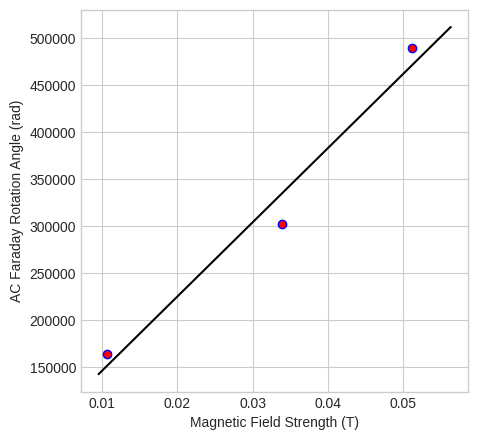

In [12]:
slope, intercept, err_slope, err_intercept, fig = PHYS231.LinearFit(
    xData=V,
    yData=W2,
    yErrors="",
    xlabel="Magnetic Field Strength",
    ylabel="AC Faraday Rotation Angle",
    xUnits="T",
    yUnits="rad",
    fill=False,
)

Optimal parameters:
a = 1908.964 +/- 550.719
b = -0.349 +/- 0.084


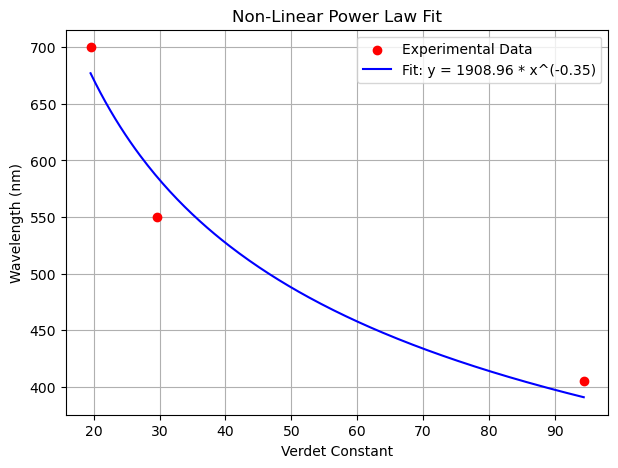

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Your data
Verdet = np.array([19.53, 29.54, 94.37])
Wavelength = np.array([700, 550, 405])

# Define a non-linear function (e.g., Power Law: y = a * x^b)
def non_linear_func(x, a, b):
    return a * (x ** b)

# Perform the curve fit
# p0 provides initial guesses for parameters [a, b] to help convergence
popt, pcov = curve_fit(non_linear_func, Verdet, Wavelength, p0=[1000, -0.5])
a_opt, b_opt = popt

# Calculate standard errors of the parameters from the covariance matrix
perr = np.sqrt(np.diag(pcov))

print(f"Optimal parameters:")
print(f"a = {a_opt:.3f} +/- {perr[0]:.3f}")
print(f"b = {b_opt:.3f} +/- {perr[1]:.3f}")

# Generate points for a smooth fit line on a plot
x_fit = np.linspace(min(Verdet), max(Verdet), 200)
y_fit = non_linear_func(x_fit, *popt)

# Plotting the results
plt.figure(figsize=(7, 5))
plt.scatter(Verdet, Wavelength, color='red', label='Experimental Data', zorder=5)
plt.plot(x_fit, y_fit, color='blue', label=f'Fit: y = {a_opt:.2f} * x^({b_opt:.2f})')
plt.xlabel('Verdet Constant')
plt.ylabel('Wavelength (nm)')
plt.title('Non-Linear Power Law Fit')
plt.legend()
plt.grid(True)
plt.show()

In [2]:
# SF-57
sf57_verdet = np.array([
    41.77,  # Red, 700 nm
    29.82,  # Green, 550 nm
    62.70,  # Purple, 405 nm
])

sf57_verdet_err = np.array([
    0.57,   # Red, 700 nm
    0.32,   # Green, 550 nm
    0.66,   # Purple, 405 nm
])

sf57_wavelength_nm = np.array([700, 550, 405])

# SF-59
sf59_verdet = np.array([
    19.53,  # Red, 700 nm
    29.54,  # Green, 550 nm
    94.37,  # Purple, 405 nm
])

sf59_verdet_err = np.array([
    0.21,   # Red, 700 nm
    0.40,   # Green, 550 nm
    1.75,   # Purple, 405 nm
])

sf59_wavelength_nm = np.array([700, 550, 405])

materials = np.array([
    "SF-57", "SF-57", "SF-57",
    "SF-59", "SF-59", "SF-59",
])

colors = np.array([
    "red", "green", "purple",
    "red", "green", "purple",
])

wavelength_nm = np.array([
    700, 550, 405,
    700, 550, 405,
])

verdet = np.array([
    41.77, 29.82, 62.70,
    19.53, 29.54, 94.37,
])

verdet_err = np.array([
    0.57, 0.32, 0.66,
    0.21, 0.40, 1.75,
])

<>:191: SyntaxWarning: invalid escape sequence '\l'
<>:191: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1541/3155957569.py:191: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("Laser wavelength, $\lambda$ (nm)", fontsize=13)


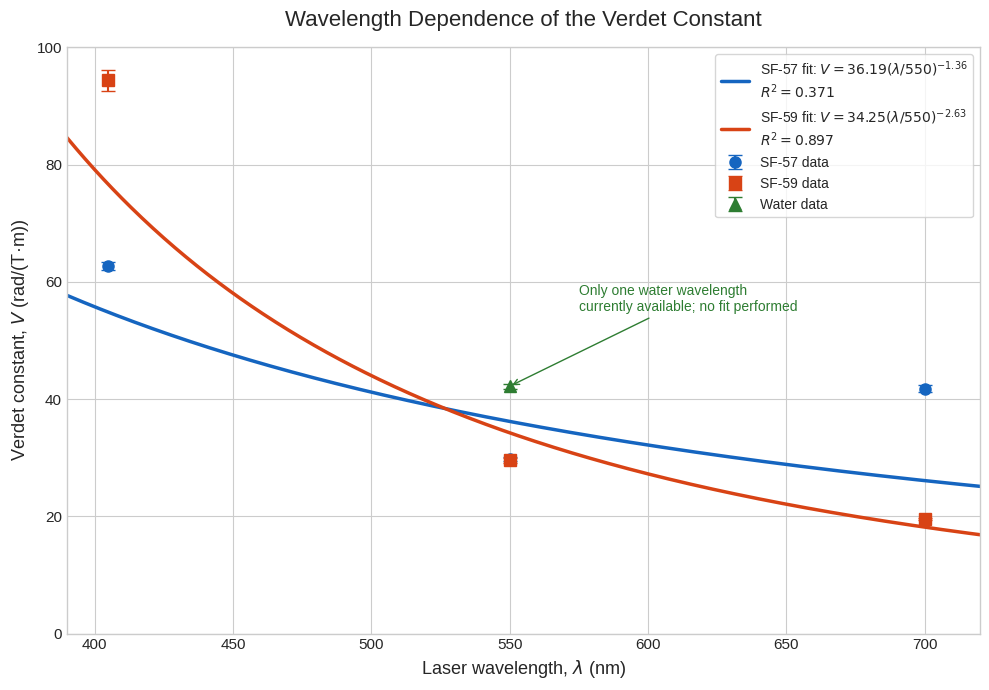

Nonlinear power-law fit results
--------------------------------
SF-57: A = 36.190 ± 0.267, B = -1.357 ± 0.039, R² = 0.371
SF-59: A = 34.249 ± 0.286, B = -2.631 ± 0.044, R² = 0.897


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# ---------------------------------------------------------------------
# Experimental data
# ---------------------------------------------------------------------

wavelength_nm = np.array([405.0, 550.0, 700.0])

# Verdet constants in rad / (T*m)
sf57_verdet = np.array([62.70, 29.82, 41.77])
sf57_error = np.array([0.66, 0.32, 0.57])

sf59_verdet = np.array([94.37, 29.54, 19.53])
sf59_error = np.array([1.75, 0.40, 0.21])

# Only one reliable water value is currently available
water_wavelength_nm = np.array([550.0])
water_verdet = np.array([42.19])
water_error = np.array([0.46])


# ---------------------------------------------------------------------
# Nonlinear model
# ---------------------------------------------------------------------

def power_law(wavelength, A, B):
    """
    Nonlinear wavelength-dependence model:

        V(lambda) = A * (lambda / 550 nm)^B
    """
    return A * (wavelength / 550.0) ** B


def calculate_r_squared(y_data, y_fit):
    residuals = y_data - y_fit
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y_data - np.mean(y_data))**2)
    return 1 - ss_res / ss_tot


def fit_material(wavelength, verdet, errors):
    """
    Fit the power-law model using uncertainty-weighted nonlinear least squares.
    """
    initial_guess = [np.mean(verdet), -1.0]

    parameters, covariance = curve_fit(
        power_law,
        wavelength,
        verdet,
        p0=initial_guess,
        sigma=errors,
        absolute_sigma=True,
        maxfev=10000,
    )

    parameter_errors = np.sqrt(np.diag(covariance))
    fitted_values = power_law(wavelength, *parameters)
    r_squared = calculate_r_squared(verdet, fitted_values)

    return parameters, parameter_errors, r_squared


# ---------------------------------------------------------------------
# Fit SF-57 and SF-59
# ---------------------------------------------------------------------

sf57_parameters, sf57_parameter_errors, sf57_r_squared = fit_material(
    wavelength_nm,
    sf57_verdet,
    sf57_error,
)

sf59_parameters, sf59_parameter_errors, sf59_r_squared = fit_material(
    wavelength_nm,
    sf59_verdet,
    sf59_error,
)


# ---------------------------------------------------------------------
# Smooth curves for plotting
# ---------------------------------------------------------------------

wavelength_fit = np.linspace(390, 720, 500)

sf57_fit = power_law(wavelength_fit, *sf57_parameters)
sf59_fit = power_law(wavelength_fit, *sf59_parameters)


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(10, 7))

# Distinct color for each material
sf57_color = "#1565C0"   # blue
sf59_color = "#D84315"   # orange/red
water_color = "#2E7D32"  # green

# Experimental points
ax.errorbar(
    wavelength_nm,
    sf57_verdet,
    yerr=sf57_error,
    fmt="o",
    color=sf57_color,
    markersize=8,
    capsize=5,
    linewidth=1.5,
    label="SF-57 data",
)

ax.errorbar(
    wavelength_nm,
    sf59_verdet,
    yerr=sf59_error,
    fmt="s",
    color=sf59_color,
    markersize=8,
    capsize=5,
    linewidth=1.5,
    label="SF-59 data",
)

ax.errorbar(
    water_wavelength_nm,
    water_verdet,
    yerr=water_error,
    fmt="^",
    color=water_color,
    markersize=9,
    capsize=5,
    linewidth=1.5,
    label="Water data",
)

# Nonlinear best-fit curves
sf57_A, sf57_B = sf57_parameters
sf57_A_err, sf57_B_err = sf57_parameter_errors

sf59_A, sf59_B = sf59_parameters
sf59_A_err, sf59_B_err = sf59_parameter_errors

ax.plot(
    wavelength_fit,
    sf57_fit,
    color=sf57_color,
    linewidth=2.5,
    label=(
        rf"SF-57 fit: "
        rf"$V={sf57_A:.2f}"
        rf"\left(\lambda/550\right)^{{{sf57_B:.2f}}}$"
        "\n"
        rf"$R^2={sf57_r_squared:.3f}$"
    ),
)

ax.plot(
    wavelength_fit,
    sf59_fit,
    color=sf59_color,
    linewidth=2.5,
    label=(
        rf"SF-59 fit: "
        rf"$V={sf59_A:.2f}"
        rf"\left(\lambda/550\right)^{{{sf59_B:.2f}}}$"
        "\n"
        rf"$R^2={sf59_r_squared:.3f}$"
    ),
)

# Add a note explaining why water has no curve
ax.annotate(
    "Only one water wavelength\ncurrently available; no fit performed",
    xy=(550, 42.19),
    xytext=(575, 55),
    arrowprops=dict(arrowstyle="->", color=water_color),
    color=water_color,
    fontsize=10,
)

# Labels and formatting
ax.set_xlabel("Laser wavelength, $\lambda$ (nm)", fontsize=13)
ax.set_ylabel("Verdet constant, $V$ (rad/(T·m))", fontsize=13)

ax.set_title(
    "Wavelength Dependence of the Verdet Constant",
    fontsize=16,
    pad=15,
)

ax.set_xlim(390, 720)
ax.set_ylim(bottom=0)

ax.tick_params(axis="both", labelsize=11)
ax.legend(fontsize=10, loc="best", frameon=True)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------------
# Print fitted parameters
# ---------------------------------------------------------------------

print("Nonlinear power-law fit results")
print("--------------------------------")

print(
    f"SF-57: A = {sf57_A:.3f} ± {sf57_A_err:.3f}, "
    f"B = {sf57_B:.3f} ± {sf57_B_err:.3f}, "
    f"R² = {sf57_r_squared:.3f}"
)

print(
    f"SF-59: A = {sf59_A:.3f} ± {sf59_A_err:.3f}, "
    f"B = {sf59_B:.3f} ± {sf59_B_err:.3f}, "
    f"R² = {sf59_r_squared:.3f}"
)

<>:195: SyntaxWarning: invalid escape sequence '\l'
<>:258: SyntaxWarning: invalid escape sequence '\l'
<>:195: SyntaxWarning: invalid escape sequence '\l'
<>:258: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1541/1371517437.py:195: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("Laser wavelength, $\lambda$ (nm)", fontsize=12)
/tmp/ipykernel_1541/1371517437.py:258: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("Laser wavelength, $\lambda$ (nm)", fontsize=12)


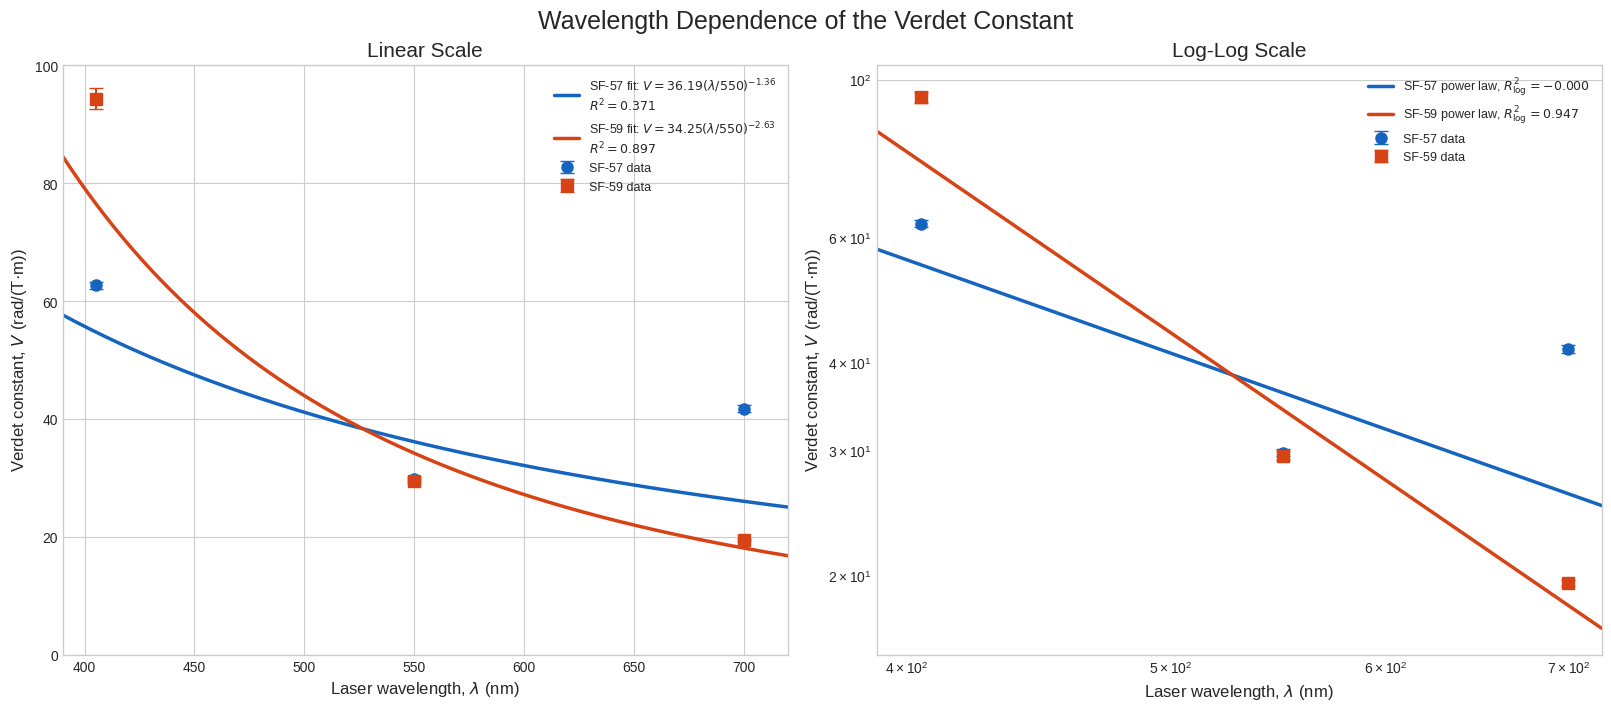

Power-law model:
V(lambda) = A * (lambda / 550 nm)^B

SF-57
A = 36.190 ± 0.267 rad/(T·m)
B = -1.357 ± 0.039
Linear-scale R² = 0.371
Log-log R² = -0.000

SF-59
A = 34.249 ± 0.286 rad/(T·m)
B = -2.631 ± 0.044
Linear-scale R² = 0.897
Log-log R² = 0.947


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# ---------------------------------------------------------------------
# Experimental data
# ---------------------------------------------------------------------

wavelength_nm = np.array([405.0, 550.0, 700.0])

# Verdet constants in rad / (T*m)
sf57_verdet = np.array([62.70, 29.82, 41.77])
sf57_error = np.array([0.66, 0.32, 0.57])

sf59_verdet = np.array([94.37, 29.54, 19.53])
sf59_error = np.array([1.75, 0.40, 0.21])


# ---------------------------------------------------------------------
# Power-law model
#
# V(lambda) = A * (lambda / 550 nm)^B
# ---------------------------------------------------------------------

def power_law(wavelength, A, B):
    return A * (wavelength / 550.0) ** B


def fit_power_law(wavelength, verdet, errors):
    """
    Weighted nonlinear power-law fit.
    """
    initial_guess = [np.mean(verdet), -1.0]

    parameters, covariance = curve_fit(
        power_law,
        wavelength,
        verdet,
        p0=initial_guess,
        sigma=errors,
        absolute_sigma=True,
        maxfev=10000,
    )

    parameter_errors = np.sqrt(np.diag(covariance))
    fitted_values = power_law(wavelength, *parameters)

    residuals = verdet - fitted_values
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((verdet - np.mean(verdet))**2)
    r_squared_linear = 1 - ss_res / ss_tot

    return parameters, parameter_errors, fitted_values, r_squared_linear


def calculate_log_r_squared(wavelength, verdet, fitted_values):
    """
    R² calculated in log-log space.
    """
    log_verdet = np.log(verdet)
    log_fitted = np.log(fitted_values)

    ss_res = np.sum((log_verdet - log_fitted) ** 2)
    ss_tot = np.sum((log_verdet - np.mean(log_verdet)) ** 2)

    return 1 - ss_res / ss_tot


# ---------------------------------------------------------------------
# Fit each material
# ---------------------------------------------------------------------

sf57_parameters, sf57_parameter_errors, sf57_fitted, sf57_r2_linear = (
    fit_power_law(
        wavelength_nm,
        sf57_verdet,
        sf57_error,
    )
)

sf59_parameters, sf59_parameter_errors, sf59_fitted, sf59_r2_linear = (
    fit_power_law(
        wavelength_nm,
        sf59_verdet,
        sf59_error,
    )
)

sf57_A, sf57_B = sf57_parameters
sf57_A_error, sf57_B_error = sf57_parameter_errors

sf59_A, sf59_B = sf59_parameters
sf59_A_error, sf59_B_error = sf59_parameter_errors

sf57_r2_log = calculate_log_r_squared(
    wavelength_nm,
    sf57_verdet,
    sf57_fitted,
)

sf59_r2_log = calculate_log_r_squared(
    wavelength_nm,
    sf59_verdet,
    sf59_fitted,
)


# ---------------------------------------------------------------------
# Smooth wavelength range for fitted curves
# ---------------------------------------------------------------------

wavelength_fit = np.geomspace(390, 720, 500)

sf57_fit = power_law(wavelength_fit, sf57_A, sf57_B)
sf59_fit = power_law(wavelength_fit, sf59_A, sf59_B)


# ---------------------------------------------------------------------
# Plot linear and log-log comparisons
# ---------------------------------------------------------------------

plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7),
    constrained_layout=True,
)

sf57_color = "#1565C0"   # blue
sf59_color = "#D84315"   # orange/red


# ---------------------------------------------------------------------
# Linear-scale plot
# ---------------------------------------------------------------------

ax = axes[0]

ax.errorbar(
    wavelength_nm,
    sf57_verdet,
    yerr=sf57_error,
    fmt="o",
    color=sf57_color,
    markersize=8,
    capsize=5,
    linewidth=1.5,
    label="SF-57 data",
)

ax.errorbar(
    wavelength_nm,
    sf59_verdet,
    yerr=sf59_error,
    fmt="s",
    color=sf59_color,
    markersize=8,
    capsize=5,
    linewidth=1.5,
    label="SF-59 data",
)

ax.plot(
    wavelength_fit,
    sf57_fit,
    color=sf57_color,
    linewidth=2.5,
    label=(
        rf"SF-57 fit: "
        rf"$V={sf57_A:.2f}"
        rf"\left(\lambda/550\right)^{{{sf57_B:.2f}}}$"
        "\n"
        rf"$R^2={sf57_r2_linear:.3f}$"
    ),
)

ax.plot(
    wavelength_fit,
    sf59_fit,
    color=sf59_color,
    linewidth=2.5,
    label=(
        rf"SF-59 fit: "
        rf"$V={sf59_A:.2f}"
        rf"\left(\lambda/550\right)^{{{sf59_B:.2f}}}$"
        "\n"
        rf"$R^2={sf59_r2_linear:.3f}$"
    ),
)

ax.set_title("Linear Scale", fontsize=15)
ax.set_xlabel("Laser wavelength, $\lambda$ (nm)", fontsize=12)
ax.set_ylabel("Verdet constant, $V$ (rad/(T·m))", fontsize=12)
ax.set_xlim(390, 720)
ax.set_ylim(bottom=0)
ax.legend(fontsize=9)


# ---------------------------------------------------------------------
# Log-log plot
# ---------------------------------------------------------------------

ax = axes[1]

ax.errorbar(
    wavelength_nm,
    sf57_verdet,
    yerr=sf57_error,
    fmt="o",
    color=sf57_color,
    markersize=8,
    capsize=5,
    linewidth=1.5,
    label="SF-57 data",
)

ax.errorbar(
    wavelength_nm,
    sf59_verdet,
    yerr=sf59_error,
    fmt="s",
    color=sf59_color,
    markersize=8,
    capsize=5,
    linewidth=1.5,
    label="SF-59 data",
)

ax.plot(
    wavelength_fit,
    sf57_fit,
    color=sf57_color,
    linewidth=2.5,
    label=(
        rf"SF-57 power law, "
        rf"$R^2_{{\log}}={sf57_r2_log:.3f}$"
    ),
)

ax.plot(
    wavelength_fit,
    sf59_fit,
    color=sf59_color,
    linewidth=2.5,
    label=(
        rf"SF-59 power law, "
        rf"$R^2_{{\log}}={sf59_r2_log:.3f}$"
    ),
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("Log-Log Scale", fontsize=15)
ax.set_xlabel("Laser wavelength, $\lambda$ (nm)", fontsize=12)
ax.set_ylabel("Verdet constant, $V$ (rad/(T·m))", fontsize=12)
ax.set_xlim(390, 720)
ax.legend(fontsize=9)


fig.suptitle(
    "Wavelength Dependence of the Verdet Constant",
    fontsize=18,
)

plt.show()


# ---------------------------------------------------------------------
# Print fit results
# ---------------------------------------------------------------------

print("Power-law model:")
print("V(lambda) = A * (lambda / 550 nm)^B")
print()

print("SF-57")
print(
    f"A = {sf57_A:.3f} ± {sf57_A_error:.3f} rad/(T·m)"
)
print(
    f"B = {sf57_B:.3f} ± {sf57_B_error:.3f}"
)
print(f"Linear-scale R² = {sf57_r2_linear:.3f}")
print(f"Log-log R² = {sf57_r2_log:.3f}")
print()

print("SF-59")
print(
    f"A = {sf59_A:.3f} ± {sf59_A_error:.3f} rad/(T·m)"
)
print(
    f"B = {sf59_B:.3f} ± {sf59_B_error:.3f}"
)
print(f"Linear-scale R² = {sf59_r2_linear:.3f}")
print(f"Log-log R² = {sf59_r2_log:.3f}")